# `lagshape` — Complete Library Guide & Interactive Reference

`lagshape` (v1.1.0) turns linear time-series processes—and real-world empirical series—into **geometric objects** in phase space $(Y_t, Y_{t-1}, \dots, Y_{t-k})$. Instead of looking solely at algebraic equations or 1D autocorrelation bars, you can inspect the **ellipsoid cloud** of lagged observations (hence I named it `lagshape`), extract its principal axes and volume, project the best linear predictor hyperplane, compare theoretical models against empirical data clouds, and track regime drift over time.

---

## Table of Contents

1. [Architecture & Core Modules](#1-architecture--core-modules)
2. [Process Layer (`lagshape.process`)](#2-process-layer-lagshapeprocess)
   - [Defining AR, MA, and ARMA Models](#21-defining-ar-ma-and-arma-models)
   - [Roots, Stationarity, Invertibility & Stability Margins](#22-roots-stationarity-invertibility--stability-margins)
   - [Theoretical Moments, Spectrum & Simulation](#23-theoretical-moments-spectrum--simulation)
3. [Geometry Layer (`lagshape.geometry`)](#3-geometry-layer-lagshapegeometry)
   - [The Lag Cloud: 2D Ellipses & 3D Ellipsoids](#31-the-lag-cloud-2d-ellipses--3d-ellipsoids)
   - [Linear Predictors & Hyperplanes](#32-linear-predictors--hyperplanes)
   - [Predictor Convergence & AR(∞) Weights](#33-predictor-convergence--ar-weights)
   - [Parameter Stability & Cycle Regions](#34-parameter-stability--cycle-regions)
   - [Comparing Two Clouds (`compare_clouds`)](#35-comparing-two-clouds-compare_clouds)
4. [Data Layer (`lagshape.data`) — Empirical Analysis & Visual Fit Verification](#4-data-layer-lagshapedata--empirical-analysis--visual-fit-verification)
   - [Loading Real Financial Data (`yfinance`, CSV) & Practice Series](#41-loading-real-financial-data-yfinance-csv--practice-series)
   - [Health Diagnostics (`diagnose`)](#42-health-diagnostics-diagnose)
   - [Model Selection & Maximum Likelihood Fitting (`select_order`, `fit_arma`)](#43-model-selection--maximum-likelihood-fitting-select_order-fit_arma)
   - [Visual & Quantitative Fit Verification (`compare_lags`, `cloud_test`, `plot_cloud`)](#44-visual--quantitative-fit-verification-compare_lags-cloud_test-plot_cloud)
   - [Out-of-Sample Walk-Forward Forecasting (`walk_forward`)](#45-out-of-sample-walk-forward-forecasting-walk_forward)
   - [Tracking Regime Drift Over Time (`rolling_cloud`)](#46-tracking-regime-drift-over-time-rolling_cloud)
5. [Visualization Layer (`lagshape.plots`)](#5-visualization-layer-lagshapeplots)
   - [Time Series & ACF/PACF (`plot_series`, `plot_acf`)](#51-time-series--acfpacf-plot_series-plot_acf)
   - [2D & 3D Cloud Visuals (`plot_cloud`, `plot_ellipses`)](#52-2d--3d-cloud-visuals-plot_cloud-plot_ellipses)
   - [Interactive Coefficient Sliders (`plot_sweep`)](#53-interactive-coefficient-sliders-plot_sweep)
   - [Stability Triangles & Convergence Dashboards (`plot_regions`, `plot_convergence`)](#54-stability-triangles--convergence-dashboards-plot_regions-plot_convergence)


## 1. Architecture & Core Modules

`lagshape` is organized into four clean layers:

| Module | Role | Key Exports |
| :--- | :--- | :--- |
| **`lagshape.process`** | Exact mathematical definition of stationary/invertible $\text{ARMA}(p, q)$ processes, root analysis, theoretical moments, spectral density, and simulation. | `ARMAProcess` |
| **`lagshape.geometry`** | Phase-space representation of $(Y_t, Y_{t-1}, \dots, Y_{t-k})$ as covariance ellipsoids, principal axes, linear prediction hyperplanes, Levinson-Durbin convergence, and parameter triangles. | `LagCloud`, `LinearPredictor`, `lag_matrix`, `predictor_convergence`, `ar_inf_weights`, `compare_clouds`, `ar2_stationary`, `ma2_invertible`, `ar2_complex_roots` |
| **`lagshape.data`** | End-to-end empirical workflow: downloading market prices (`yfinance`) or reading CSVs, statistical diagnostics, MLE fitting, parametric bootstrap cloud testing, walk-forward validation, and rolling regime tracking. | `load_prices`, `read_series`, `to_returns`, `example_series`, `diagnose`, `select_order`, `fit_arma`, `compare_lags`, `cloud_test`, `walk_forward`, `rolling_cloud` |
| **`lagshape.plots`** | Interactive Plotly figures (lazy-loaded) matching the phase-space coordinate convention $(Y_{t-1}, Y_t, Y_{t-2})$ plus Matplotlib snapshots for rolling windows. | `plot_cloud`, `plot_series`, `plot_acf`, `plot_sweep`, `plot_regions`, `plot_convergence`, `plot_ellipses` |

> **Coordinate Convention Note:** Internally, `lagshape.geometry` orders vectors chronologically from present to past: $(Y_t, Y_{t-1}, \dots, Y_{t-k})$. When plotting in `lagshape.plots`, axes are automatically permuted to $(Y_{t-1}, Y_t)$ in 2D and $(Y_{t-1}, Y_t, Y_{t-2})$ in 3D so $Y_t$ sits cleanly on the vertical/response axis.


In [1]:
import numpy as np
import pandas as pd

import lagshape as ls
import lagshape.data as lsd
import lagshape.plots as lsp

# Optional: switch Plotly theme globally (default is "plotly_dark")
lsp.TEMPLATE = "plotly_white"
print("lagshape version:", ls.__version__)

lagshape version: 0.3.0


## 2. Process Layer (`lagshape.process`)

### 2.1 Defining AR, MA, and ARMA Models

`ARMAProcess` uses the standard positive-sign convention on both sides of the equation:
$$Y_t = \sum_{i=1}^p \phi_i Y_{t-i} + \varepsilon_t + \sum_{j=1}^q \theta_j \varepsilon_{t-j}, \qquad \varepsilon_t \sim \text{WN}(0, \sigma^2)$$


In [2]:
# 1. Pure AR(1)
ar1 = ls.ARMAProcess(ar=[0.85], sigma=1.0)

# 2. Pure MA(1) {single-lag shock memory}
ma1 = ls.ARMAProcess(ma=[-0.5], sigma=0.3)

# 3. AR(2) with complex roots: damped oscillatory pseudo-cycle
ar2_cycle = ls.ARMAProcess(ar=[1.2, -0.6], sigma=1.0)

# 4. Mixed ARMA(2, 1)
arma21 = ls.ARMAProcess(ar=[0.6, 0.2], ma=[0.4], sigma=1.5)

for model in (ar1, ma1, ar2_cycle, arma21):
    print(f"{model}  -> p={model.p}, q={model.q}, Var={model.variance:.3f}")


ARMAProcess(ar=[0.85], ma=[], sigma=1.0)  -> p=1, q=0, Var=3.604
ARMAProcess(ar=[], ma=[-0.5], sigma=0.3)  -> p=0, q=1, Var=0.112
ARMAProcess(ar=[1.2, -0.6], ma=[], sigma=1.0)  -> p=2, q=0, Var=3.571
ARMAProcess(ar=[0.6, 0.2], ma=[0.4], sigma=1.5)  -> p=2, q=1, Var=9.429


### 2.2 Roots, Stationarity, Invertibility & Stability Margins

A process is **stationary** iff all roots of the AR polynomial $1 - \phi_1 z - \dots - \phi_p z^p = 0$ lie strictly outside the unit circle ($|z| > 1$), and **invertible** iff all roots of the MA polynomial $1 + \theta_1 z + \dots + \theta_q z^q = 0$ lie outside the unit circle. `ar_margin` and `ma_margin` measure $\min |\text{root}| - 1$, telling us how close a process is to an explosive or non-invertible boundary. We will use `is_stationary`, `is_invertible`, `has_complex_roots` and `margin` here once a process is defined on which we can use them.

In [3]:
# Near-unit-root AR(1) vs oscillatory AR(2) vs non-stationary random walk
near_unit = ls.ARMAProcess(ar=[0.98])
non_stat  = ls.ARMAProcess(ar=[1.0])
non_inv   = ls.ARMAProcess(ma=[1.2])

for name, m in [("AR(1) phi=0.98", near_unit),
                ("AR(2) cycle", ar2_cycle),
                ("Random walk phi=1.0", non_stat),
                ("Non-invertible MA(1)", non_inv)]:
    print(f"{name:22s} | stationary={str(m.is_stationary):5s} | invertible={str(m.is_invertible):5s} "
          f"| complex={str(m.has_complex_roots):5s} | margin={m.margin:.4f}")


AR(1) phi=0.98         | stationary=True  | invertible=True  | complex=False | margin=0.0204
AR(2) cycle            | stationary=True  | invertible=True  | complex=True  | margin=0.2910
Random walk phi=1.0    | stationary=False | invertible=True  | complex=False | margin=0.0000
Non-invertible MA(1)   | stationary=True  | invertible=False | complex=False | margin=-0.1667


### 2.3 Theoretical Moments, Spectrum & Simulation

Once defined, `ARMAProcess` computes exact autocovariances $\gamma(h)$, autocorrelations $\rho(h)$, partial autocorrelations ($PACF$), power spectral density $f(\omega)$, and simulated sample paths with automatic burn-in computed from the AR root decay rate.

In [4]:
# Exact moments of ARMA(2, 1)
print("Autocovariances (lags 0...4):", arma21.autocov(4).round(3))
print("ACF             (lags 0...4):", arma21.acf(4).round(3))
print("PACF            (lags 0...4):", arma21.pacf(4).round(3))

# Spectral density across frequencies [0, pi]
freqs = np.linspace(0, np.pi, 5)
print("Spectral density at 5 freqs:", arma21.spectral_density(freqs).round(3))

Autocovariances (lags 0...4): [9.429 8.196 6.804 5.721 4.794]
ACF             (lags 0...4): [1.    0.869 0.722 0.607 0.508]
PACF            (lags 0...4): [1.    0.869 0.    0.056 0.   ]
Spectral density at 5 freqs: [17.547  0.857  0.231  0.102  0.066]


You can also pass custom heavy-tailed `innovations` (e.g., Student-$t$ shocks), that is, we will simulate the exact `ar2_cycle` process we had before but this time with Student-$t$ white noise instead of Gaussian one. Then we will be able to compare how tail thickness affects the resulting time series while keeping the underlying linear dynamics and noise scale identical.

We will use the `lambda parameters: expression` to define 

```python
def f(parameters):
    expression
```
We have `ARMAProcess.simulate(..., innovations=...)` that expects `innovations` to have entry `f(rng, size)` which we will modify.

In [5]:
# Gaussian vs Student-t innovations (unit-variance rescaled one)
# Gaussian, uses the default rng.standard_normal
sim_norm = ar2_cycle.simulate(n=500, seed=3302)
# student t
t_innov = lambda rng, size: rng.standard_t(df=4, size=size) / np.sqrt(4 / (4 - 2))
sim_fat  = ar2_cycle.simulate(n=500, seed=42, innovations=t_innov)
print(f"Simulated stds -> Gaussian: {sim_norm.std():.3f}, Student-t: {sim_fat.std():.3f}")

Simulated stds -> Gaussian: 1.875, Student-t: 1.987


## 3. Geometry Layer (`lagshape.geometry`)

### 3.1 The Lag Cloud: 2D Ellipses & 3D Ellipsoids

Stacking a time series into lag vectors $(Y_t, Y_{t-1}, \dots, Y_{t-k})$ via `lag_matrix(y, lags)` creates a point cloud in $\mathbb{R}^{k+1}$. For any stationary linear process, the covariance matrix $\Sigma$ is symmetric Toeplitz, defining an **ellipsoid**:
* **`lags=1` (2D Ellipse):** Captures immediate persistence $(Y_t, Y_{t-1})$. Positive $\phi_1$ stretches the ellipse along the $45^\circ$ diagonal; negative $\phi_1$ stretches it along the $-45^\circ$ diagonal.
* **`lags=2` (3D Ellipsoid):** Captures curvature and oscillatory spirals across $(Y_t, Y_{t-1}, Y_{t-2})$.

`LagCloud` exposes identical geometric properties whether constructed from exact theory (`LagCloud.from_process`) or finite data (`LagCloud.from_data`): eigenvalues, principal axis directions, semi-axis lengths, `elongation` ($\lambda_{\max}^{1/2} / \lambda_{\min}^{1/2}$), `volume(radius)`, and `boundary_points(n, radius)`.

- `axis_length` returns `np.sqrt(self._eigvals)`, that is, axis-length is the standard deviation.
- `elongation` measures how stretched out the cloud is by dividing the longest semi-axis length by the shortest semi-axis length (`axis_lengths[0] / axis_lengths[-1]`). A value near $1$ means round-sih cloud (like pure white noise) and a large value means a thin, stretched, needle-like cloud (strong autocorrelation).

**Remark:** Note that the spread for AR(1) with parameter 0.85 and -0.85 are different of course. Eigen vector of one of them is $90^\circ$ rotated version of the other but the above mentioned features are the same (eigen values, elongation, etc). So, they should match for both of them.

Defining the process is easy. Now we will look at the lag-matrix which is in `LagCloud`; so we have to write `ls.LagCloud.from_process(process, lags=)`.

In [6]:
# 2D Cloud Examples (lags=1)
cloud_ar1_pos = ls.LagCloud.from_process(ls.ARMAProcess(ar=[0.85]), lags=1)
cloud_ar1_neg = ls.LagCloud.from_process(ls.ARMAProcess(ar=[-0.85]), lags=1)
cloud_white   = ls.LagCloud.from_process(ls.ARMAProcess(), lags=1)

for label, c in [("White Noise (2D)", cloud_white),
                 ("AR(1) +0.85 (2D)", cloud_ar1_pos),
                 ("AR(1) -0.85 (2D)", cloud_ar1_neg)]:
    print(f"{label:17s} | axis_lengths={c.axis_lengths.round(2)} | elongation={c.elongation:5.2f} "
          f"| 2σ area={c.volume(radius=2.0):6.2f} | boundary_points={c.boundary_points(n=40, radius=2.0).shape}")

# 3D Cloud Examples (lags=2)
cloud_cycle_3d = ls.LagCloud.from_process(ar2_cycle, lags=2)
cloud_data_3d  = ls.LagCloud.from_data(sim_norm, lags=2)

print("\n3D Theoretical Cycle Cloud:", cloud_cycle_3d)
print("  3D semi-axis lengths :", cloud_cycle_3d.axis_lengths.round(3))
print("  3D elongation        :", round(cloud_cycle_3d.elongation, 3))
print("  3D 2σ volume         :", round(cloud_cycle_3d.volume(radius=2.0), 3))
print("  Boundary mesh shape  :", cloud_cycle_3d.boundary_points(n=40, radius=2.0).shape)


White Noise (2D)  | axis_lengths=[1. 1.] | elongation= 1.00 | 2σ area= 12.57 | boundary_points=(40, 2)
AR(1) +0.85 (2D)  | axis_lengths=[2.58 0.74] | elongation= 3.51 | 2σ area= 23.85 | boundary_points=(40, 2)
AR(1) -0.85 (2D)  | axis_lengths=[2.58 0.74] | elongation= 3.51 | 2σ area= 23.85 | boundary_points=(40, 2)

3D Theoretical Cycle Cloud: LagCloud(lags=2, source='process')
  3D semi-axis lengths : [2.817 1.581 0.53 ]
  3D elongation        : 5.31
  3D 2σ volume         : 79.161
  Boundary mesh shape  : (20, 40, 3)


The `boundary_points` command is just for your sanity check here. It is very useful internally when we get to drawing the ellipse. The radius is set at `2.0` because we want the 2-sigma ellipse (or ellipsoid). When we call `boundary_points(n=40, radius=2.0)` on a 2D cloud (`lags=1`), it generates a ring of dots around the perimeter of the ellipse with:
- $40$ (rows): The number of sample points placed around the $360^\circ$ ($0$ to $2\pi$) perimeter of the ellipse. Think of it as a 40-sided polygon approximating a smooth oval.
- $2$ (columns): The 2 coordinates of each dot $(Y_t, Y_{t-1})$.

So `(40, 2)` is literally a table of 40 dots, each having 2 coordinates (`[y_t, y_{t-1}]`) that you connect with a line (`plt.plot` or `go.Scatter`) to draw the ellipse.

For 3D it is a bit different. `(20, 40, 3)` is latitude-by-longitude grid covering a 3D shell. It comes from the formulae that I fixed as $(n//2, n, 3)$.
- $20$ (rows / latitude rings): `n // 2` slices running from the North Pole to the South Pole ($v$ from $0$ to $\pi$, i.e., $180^\circ$). There are half as many steps ($20$ instead of $40$) because pole-to-pole is half a circle ($180^\circ$) rather than a full circle ($360^\circ$).
- $40$ (columns / longitude points): `n` points wrapping all the way around the equator ($u$ from $0$ to $2\pi$, i.e., $360^\circ$) on each of those 20 rings.
- $3$ (depth): The 3 coordinates of every single grid intersection on that shell: $(Y_t, Y_{t-1}, Y_{t-2})$.

So `(20, 40, 3)` is literally a $20 \times 40$ grid of $800$ points sitting on the outer surface of the 3D ellipsoid, where every point has $3$ coordinates—formatted specifically as a 2D surface grid so Plotly's `go.Surface(x=..., y=..., z=...)` can shade the 3D shell directly.

### 3.2 Linear Predictors & Hyperplanes

Slicing the lag cloud at known past coordinates $(Y_{t-1}, \dots, Y_{t-k})$ yields the conditional expectation—a **best-guess line (2D) or hyperplane (3D)** returned by `cloud.predictor()` as a `LinearPredictor` object.


In [7]:
pred_3d = cloud_cycle_3d.predictor()
print("True AR(2) coefficients     :", ar2_cycle.ar)
print("Cloud hyperplane weights    :", pred_3d.weights.round(4))
print("Intercept                   :", round(pred_3d.intercept, 4))
print("One-step error std (sigma)  :", round(pred_3d.error_std, 4))
print("Theoretical R^2             :", round(pred_3d.r_squared, 4))

# Generate in-sample predictions on simulated series
y_hat = pred_3d.predict(sim_norm)
print("First 5 predicted values    :", y_hat[:5].round(3))

True AR(2) coefficients     : [ 1.2 -0.6]
Cloud hyperplane weights    : [ 1.2 -0.6]
Intercept                   : 0.0
One-step error std (sigma)  : 1.0
Theoretical R^2             : 0.72
First 5 predicted values    : [ 0.713  0.235 -0.751 -0.302  1.11 ]


### 3.3 Predictor Convergence & AR(∞) Weights

As you allow more lags $k = 1, 2, \dots, K$, how do the best linear predictor weights evolve? `predictor_convergence` runs the Levinson-Durbin recursion to show:
1. Weight vectors $\hat{\phi}^{(k)}$ converging toward the infinite-order `ar_inf_weights` $\pi_j$ (for invertible models).
2. Prediction error variance dropping toward the irreducible innovation floor $\sigma^2$.
3. The oldest-lag weight $\hat{\phi}_{k,k}$, which equals the **PACF** at lag $k$.


In [8]:
conv = ls.predictor_convergence(arma21, max_lags=8)
pi_inf = ls.ar_inf_weights(arma21, nterms=8)

df_conv = pd.DataFrame({
    "lag_k": conv.lags,
    "PACF (last_weight)": conv.last_weight.round(4),
    "error_variance": conv.error_variance.round(4),
    "AR_inf_weight_pi_k": pi_inf.round(4),
})
print(f"Irreducible noise floor sigma^2 = {arma21.sigma**2:.4f}")
df_conv


Irreducible noise floor sigma^2 = 2.2500


,lag_k,PACF (last_weight),error_variance,AR_inf_weight_pi_k
0,1,0.8693,2.3033,1.0000
1,2,-0.1397,2.2583,-0.2000
2,3,0.0557,2.2513,0.0800
3,4,-0.0223,2.2502,-0.0320
4,5,0.0089,2.2500,0.0128
5,6,-0.0036,2.2500,-0.0051
6,7,0.0014,2.2500,0.0020
7,8,-0.0006,2.2500,-0.0008


### 3.4 Parameter Stability & Cycle Regions

For second-order models, `lagshape.geometry` provides vectorized boolean checks (`ar2_stationary`, `ma2_invertible`, `ar2_complex_roots`) and exact boundary vertices (`ar2_triangle`, `ma2_triangle`, `ar2_complex_boundary`). The exact boundary will be important for us when we plot the stability triangles in the last section.

In [9]:
candidates = [(0.5, 0.3), (1.2, -0.6), (1.5, -0.8), (0.8, 0.4)]
for p1, p2 in candidates:
    print(f"phi=({p1:4.1f}, {p2:4.1f}) -> stationary={str(ls.ar2_stationary(p1, p2)):5s} "
          f"| complex_roots={str(ls.ar2_complex_roots(p1, p2)):5s}")


phi=( 0.5,  0.3) -> stationary=True  | complex_roots=False
phi=( 1.2, -0.6) -> stationary=True  | complex_roots=True 
phi=( 1.5, -0.8) -> stationary=True  | complex_roots=True 
phi=( 0.8,  0.4) -> stationary=False | complex_roots=False


### 3.5 Comparing Two Clouds (`compare_clouds`)

`compare_clouds(a, b)` quantifies the geometric discrepancy between any two clouds of equal dimension (e.g., finite sample vs. true process, or two competing models):
* `cov_rel_error`: Relative Frobenius norm $\frac{\|\Sigma_a - \Sigma_b\|_F} {\|\Sigma_b\|_F}$ ($0\,\sim$ exact match).
* `axis_length_ratio` & `volume_ratio`: Scale/stretch mismatch ($1$ = exact match).
* `axis_angles_deg`: Principal axis rotation mismatch in degrees ($0^\circ$ = aligned).


In [10]:
comp = ls.compare_clouds(cloud_data_3d, cloud_cycle_3d)
print(f"Relative covariance error : {comp.cov_rel_error:.4f}")
print(f"Axis length ratios        : {comp.axis_length_ratio.round(3)}")
print(f"Elongation ratio          : {comp.elongation_ratio:.3f}")
print(f"Volume ratio              : {comp.volume_ratio:.3f}")
print(f"Principal axis angles (°) : {comp.axis_angles_deg.round(2)}")


Relative covariance error : 0.0320
Axis length ratios        : [0.984 1.01  1.02 ]
Elongation ratio          : 0.964
Volume ratio              : 1.013
Principal axis angles (°) : [0.4  0.34 0.25]


## 4. Data Layer (`lagshape.data`) — Empirical Analysis & Visual Fit Verification

The `lagshape.data` module bridges raw empirical time series and geometric phase-space analysis. Specifically, it lets you:
1. **Ingest market data** directly from Yahoo Finance (`load_prices`) or CSV files (`read_series`), convert prices to stationary returns (`to_returns`), or generate realistic financial benchmarks (`example_series` with bid-ask bounce, GARCH volatility clustering, spreads, and cycles).
2. **Run statistical health checks** (`diagnose`) for stationarity (ADF), serial correlation (Ljung-Box), and volatility clustering (Ljung-Box on squared returns).
3. **Select and fit ARMA models** (`select_order`, `fit_arma`) by maximum likelihood, automatically returning a fitted `ARMAProcess` (`fit.model`).
4. **Verify whether an ARMA fit actually matches the data—both visually and statistically:**
   * **Visual verification (`plot_cloud` with `model=fit.model`):** Overlays the model's exact theoretical $2\sigma$ ellipse/ellipsoid (solid teal) directly on top of the empirical scatter points and the data's own sample ellipse (dashed orange) in 2D or 3D. If the fitted ARMA model captures the data's dependence geometry, the two ellipses align in tilt, elongation, and scale; if the data has fat tails, outliers, or nonlinear regimes, you immediately see points spilling outside the theoretical boundary or axes tilting away.
   * **Multi-lag geometric audit (`compare_lags`):** Checks `cov_rel_error`, `elongation`, `volume_ratio`, and $R^2$ across lags $1, 2, 3, 4, 5$. A model might match lag 1 by construction yet fail at lags 3–5.
   * **Parametric bootstrap goodness-of-fit (`cloud_test` with `refit=(p, q)`):** Simulates synthetic series from the fitted model, re-fits each one, and computes an exact $p$-value testing whether the observed cloud mismatch is larger than chance.
5. **Test genuine out-of-sample forecasting power** (`walk_forward`) using rolling or expanding lag-cloud hyperplanes and the Clark-West nested test.
6. **Detect structural breaks & regime drift** (`rolling_cloud`) by sliding a window across time and plotting a $2\times 3$ grid of evolving 2D lag clouds.


### 4.1 Loading Real Financial Data (`yfinance`, CSV) & Practice Series

Before we can study a time series or draw its lag cloud, we need numbers in a sequence. In Section 4.1, we are simply getting two sets of numbers ready. We will have a main series to work with and a second practice series (`arch_returns`) that behaves differently so we can compare how lagshape reacts to different kinds of behavior. The main series we work with will be downloaded stock prices from market (using `yfinance`) and in case of some issue, we will fall back to a built-in practice series already available in the library. "SPY" is a short code for an exchange-traded fund (ETF) that tracks the S&P 500 index (a basket of roughly 500 large U.S. public companies). 

Inside `lagshape./data.py` file we have already imported `yfinance` as `yf`. So we can use `load_prices(Name, start="", end="")` and it will download the data. Below we demonstrate both `load_prices("SPY", ...)` (with an automatic fallback to `example_series("roll")` if offline) and `example_series` for controlled experiments.

`except Exception as e: ... returns = lsd.example_series("roll", n=1500, seed=7)` wraps the `yfinance` call in a try/except block so the notebook still runs if internet access is unavailable or `yfinance` isn't installed/returns empty data. If `load_prices` fails, it falls back to `example_series("roll", n=1500, seed=7)`, generating `1500` business-day observations starting `2020-01-01` from the Roll bid-ask bounce model (an $\text{MA}(1)$-like return process with shocks of sd `0.3` and spread term `0.3 * (q_t - q_{t-1}))`.

The contrast series is `"arch"` which simulates a $\text{GARCH}(1,1)$ return series (`alpha = 0.08`, `beta = 0.90`, daily vol around `1%`). Its defining trait is volatility clustering and fat tails; the returns themselves have little linear autocorrelation from step to step, but quiet days cluster with quiet days and stormy days cluster with stormy days (seen when looking at squared returns). **Using "arch" gives you a contrast case where simple linear ARMA models miss the volatility clustering**. This was the point.

In [11]:
# real SPY daily prices via yfinance; fallback if offline
try:
    prices = lsd.load_prices("SPY", start="2020-01-01", end="2025-12-31")
    returns = lsd.to_returns(prices, kind="log")  #demeans
    series_name = "SPY Log Returns (2020–2025)"
    print(f"Downloaded {len(prices)} daily SPY prices -> {len(returns)} log returns.")
except Exception as e:
    print(f"yfinance unavailable ({e}); using synthetic 'roll' bid-ask bounce returns.")
    returns = lsd.example_series("roll", n=1500, seed=7)
    series_name = "Roll Bid-Ask Bounce Returns (MA(1))"
print(returns.head(n=10))  #by default head(n=5)

# load a GARCH(1,1) series to contrast linear fit vs volatility clustering
arch_returns = lsd.example_series("arch", n=1500, seed=7)
print("\n",f"Date")
print(arch_returns.head(n=6))

Downloaded 1507 daily SPY prices -> 1506 log returns.
Date
2020-01-03   -0.007601
2020-01-06    0.003808
2020-01-07   -0.002816
2020-01-08    0.005315
2020-01-09    0.006758
2020-01-10   -0.002882
2020-01-13    0.006854
2020-01-14   -0.001526
2020-01-15    0.002257
2020-01-16    0.008284
Name: SPY, dtype: float64

 Date
2020-01-01    0.000012
2020-01-02    0.002865
2020-01-03   -0.002534
2020-01-06   -0.007937
2020-01-07   -0.004029
2020-01-08   -0.008529
Freq: B, Name: arch, dtype: float64


The first line of this output "Downloaded 1507 daily SPY prices -> 1506 log returns." means we are no longer going to need the "fall-back" since download was completed. A small technicality is `to_return(prices, kind-"log")` computes the day-to-day change `np.log(p).diff().dropna()`. Because there is no "previous day" before the very first price observation, `.diff()` creates a missing value (`NaN`) on the first date, and `.dropna()` removes it. Hence, leaving $1,506$ return values.

### 4.2 Health Diagnostics (`diagnose`)

Before fitting any ARMA model, `diagnose(y)` runs a quick check for four things at once. It tells you basic summary numbers, whether the series is stable enough to model (stationarity), whether today's value relates to past values, and whether big/small swings tend to cluster together. `diagnose` takes a sequence `y` and a lag count `nlags` (default 20, requiring at least `3 * nlags` observations).
* **Tail weight:** `skew` and `excess_kurtosis` ($0$ for normal; high values warn of fat tails).
* **Stationarity:** Augmented Dickey-Fuller (`adf_pvalue < 0.05` indicates no unit root).
* **Linear memory:** Ljung-Box on $Y_t$ (`ljung_box_pvalue < 0.05` indicates linear autocorrelation worth modeling).
* **Nonlinear volatility clustering:** Ljung-Box on $(Y_t - \bar{Y})^2$ (`ljung_box_sq_pvalue < 0.05` indicates ARCH/GARCH effects that a pure linear ARMA ellipse cannot capture).

In [12]:
print(f"=== Diagnostics: {series_name} ===")
print(lsd.diagnose(returns, nlags=20))  

print("\n=== Diagnostics: GARCH(1,1) Returns ===")
print(lsd.diagnose(arch_returns, nlags=20))

=== Diagnostics: SPY Log Returns (2020–2025) ===
observations            1506
mean / std              0.0005553 / 0.0131
skewness                -0.559
excess kurtosis         13.39    (0 = normal; much larger = fat tails)
ADF p-value             0.0000  -> looks stationary?             yes
Ljung-Box p (lag 20)   0.0000  -> autocorrelated?                yes
Ljung-Box p, squares    0.0000  -> volatility clustering?           yes

=== Diagnostics: GARCH(1,1) Returns ===
observations            1500
mean / std              -0.0004671 / 0.01016
skewness                0.359
excess kurtosis         3.76    (0 = normal; much larger = fat tails)
ADF p-value             0.0000  -> looks stationary?             yes
Ljung-Box p (lag 20)   0.0334  -> autocorrelated?                yes
Ljung-Box p, squares    0.0000  -> volatility clustering?           yes



Why did we run it on both `returns` and `arch_returns`?

We see that both has volatility clustering and we can already guess that ARMA fitting will not be good enough. We will continue anyway.

### 4.3 Model Selection & Maximum Likelihood Fitting (`select_order`, `fit_arma`)

Once you have a stationary series (like returns) and know its basic health from `diagnose`, you want to pick a reasonable ARMA$(p, q)$ formula and estimate its numbers from the data. Instead of guessing `p` and `q` blindly, we first tests several candidate combinations of `(p, q)`, ranks which ones balance accuracy against simplicity, and then fits the winning model to the data.

`select_order` scans a grid of $(p, q)$ orders and ranks them by AIC or BIC (the standard penalty based ARIMA model fitting techniques) which is for us to choose.
```python
select_order(y, max_p=3, max_q=2, ic="bic")
select_order(y, max_p=2, max_q=4, ic="aic")
```
has $12(4*3)$ and $15(3*5)$ (p, q) pair combinations under BIC and AIC respectively. The table will show both AIC and BIC but it will be arranged based on what penalty method we choose. `loglik` is log-likelihood ratio (high signals better chance of fitting). These are from standard Time-Series Theory.

`fit_arma(y, order=(p, q), demean=True)` fits the chosen specification and wraps the estimated parameters inside a `Fit` dataclass whose `.model` attribute is a ready-to-use `ARMAProcess`. It uses `statsmodel`'s `ARIMA`.

In [13]:
# Rank ARMA(p, q) candidates up to p=2, q=2 by BIC
order_table = lsd.select_order(returns, max_p=2, max_q=2, ic="bic")
print("Top ARMA candidates by BIC:")
print(order_table.head())

# Fit the top-ranked order
best_p, best_q = int(order_table.loc[0, "p"]), int(order_table.loc[0, "q"])   #since already arranged, locate row 0, col "p" or "q"
if (best_p, best_q) == (0, 0):
    # if white noise wins on BIC, also fit ARMA(1, 1) to inspect its geometry
    fit = lsd.fit_arma(returns, order=(1, 1))
else:
    fit = lsd.fit_arma(returns, order=(best_p, best_q))

print("\n" + str(fit))
print("\nExtracted ARMAProcess:", fit.model)

Top ARMA candidates by BIC:
   p  q          aic          bic       loglik
0  2  0 -8825.049169 -8803.780320  4416.524585
1  0  2 -8823.721202 -8802.452353  4415.860601
2  1  0 -8813.590458 -8797.638821  4409.795229
3  1  2 -8823.132564 -8796.546502  4416.566282
4  2  1 -8822.771702 -8796.185640  4416.385851

ARMA(2, 0) fit on 1506 observations   AIC -8825.05  BIC -8803.78
        estimate  std_err  p_value
const     0.0006   0.0003   0.1041
ar.L1    -0.1386   0.0118   0.0000
ar.L2     0.0944   0.0113   0.0000
sigma2    0.0002   0.0000   0.0000

Extracted ARMAProcess: ARMAProcess(ar=[-0.13863673888604197, 0.09437844024485662], ma=[], sigma=0.012882232328901441)


You can try to change the max_p and max_q to give more flexibility and may be the the fitted model will no longer be pure AR. We can play around with that. Let us try max_p=3 and max_q=4. If we arrange based on BIC, we get another AR(2) process but if we go by AIC, we get a MA(3) process.

In [14]:
# Rank ARMA(p, q) candidates up to p=3, q=4 by AIC
order_table = lsd.select_order(returns, max_p=3, max_q=4, ic="aic")
print("Top ARMA candidates by BIC:")
print(order_table.head(20))

best_p, best_q = int(order_table.loc[0, "p"]), int(order_table.loc[0, "q"])   #since already arranged, locate row 0, col "p" or "q"
if (best_p, best_q) == (0, 0):
    # if white noise wins on BIC, also fit ARMA(1, 1) to inspect its geometry
    fit = lsd.fit_arma(returns, order=(1, 1))
else:
    fit = lsd.fit_arma(returns, order=(best_p, best_q))

print("\n" + str(fit))
print("\nExtracted ARMAProcess:", fit.model)

Top ARMA candidates by BIC:
    p  q          aic          bic       loglik
0   0  3 -8828.630119 -8802.044057  4419.315060
1   0  4 -8828.513492 -8796.610218  4420.256746
2   1  4 -8826.554974 -8789.334487  4420.277487
3   3  2 -8826.527370 -8789.306883  4420.263685
4   1  3 -8826.386439 -8794.483165  4419.193220
5   2  0 -8825.049169 -8803.780320  4416.524585
6   2  4 -8824.948861 -8782.411162  4420.474431
7   0  2 -8823.721202 -8802.452353  4415.860601
8   3  0 -8823.301732 -8796.715670  4416.650866
9   2  3 -8823.172529 -8785.952042  4418.586265
10  1  2 -8823.132564 -8796.546502  4416.566282
11  3  4 -8822.807527 -8774.952615  4420.403763
12  2  1 -8822.771702 -8796.185640  4416.385851
13  2  2 -8822.303977 -8790.400702  4417.151988
14  3  1 -8821.506567 -8789.603293  4416.753284
15  1  1 -8815.216589 -8793.947739  4411.608295
16  3  3 -8813.658476 -8771.120776  4414.829238
17  1  0 -8813.590458 -8797.638821  4409.795229
18  0  1 -8807.468597 -8791.516959  4406.734298
19  0  0 -87

### 4.4 Visual & Quantitative Fit Verification (`compare_lags`, `cloud_test`, `plot_cloud`)

Fitting an ARMA model gives you a set of estimated numbers, but fitting alone doesn't prove the model actually matches how the data behaves. Here is how you verify whether `fit.model` actually fits the empirical data:
1. **`compare_lags(returns, fit)`**: Checks geometric agreement across lags 1 to 5.

   A model might look okay if you only look one step back (`lags=1`), yet fail when you look several steps back (`lags=3, 4, 5`). `compare_lags` loops over each lag count `k` in `lags` and builds two `LagCloud` objects - one from the actual data (`LagCloud.from_data(v, k)`) and one from the fitted model (`LagCloud.from_process(m, k)`).   It then calls `compare_clouds(d, t)` and collects a table with one row per lag count `k` containing the geometric tests we saw before such as `cov_rel_error`, `elongation`, etc. We will see in the output below.
   
2. **`cloud_test(returns, fit, lags=2, refit=fit.order)`**: Parametric bootstrap test—if `p_value` is small ($< 0.05$), the data's lag cloud deviates significantly from what the fitted ARMA process generates.

   Even when a model is true, a finite sample of data will have some random mismatch (`cov_rel_error`) compared to the exact model cloud. `cloud_test` tests whether your observed mismatch is unusually large compared to what the model itself produces on fake ("simulated") data of the same length. However, since this is testing the "**clouds**", note that, this test only second-order structure (variances and covariances); it does not check fat tails or volatility clustering.
   
4. **Visual Overlay (`plot_cloud(returns, model=fit.model, lags=1)` and `lags=2`)**: Plots the raw data points alongside both the **fitted model's exact $2\sigma$ ellipse** (solid teal) and the **empirical sample's $2\sigma$ ellipse** (dashed orange).

In [15]:
# Quantitative multi-lag comparison (lags 1..5)
lag_audit = lsd.compare_lags(returns, fit, lags=(1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20))
print("Multi-lag geometric comparison (Data vs Fitted Model):")
print(lag_audit.round(4))

# Parametric bootstrap cloud test (refitting on each simulation for honest p-value)
ctest = lsd.cloud_test(returns, fit, lags=2, n_sim=100, seed=42, refit=fit.order)
print("\n" + str(ctest))


Multi-lag geometric comparison (Data vs Fitted Model):
      cov_rel_error  elongation_data  elongation_model  volume_ratio  r2_data  \
lags                                                                            
1            0.0072           1.1670            1.1754        1.0001   0.0235   
2            0.0133           1.2401            1.2524        1.0027   0.0321   
3            0.0231           1.2907            1.3088        1.0065   0.0323   
4            0.0498           1.3342            1.3446        1.0074   0.0400   
5            0.0706           1.3581            1.3860        1.0076   0.0423   
6            0.1031           1.3627            1.4065        1.0040   0.0506   
7            0.1408           1.4227            1.4263        0.9952   0.0613   
8            0.1729           1.4814            1.4414        0.9845   0.0660   
9            0.2057           1.5379            1.4520        0.9681   0.0780   
10           0.2300           1.5806            1.4627

Since we are investigating the geometric clouds, notice the first table - the volume ratio in particular because if the volumes are different it is safe to assume that the hyper-ellipsoids are different! The two clouds are really good match upto lag $6/7$-ish beyond which it falters a bit but it is still fine. Note at lag $10$, it is really bad. The volume ratio is far from $1$ which means in $\mathbb{R}^{11}$ (lag space with $10$ past data point) and beyond, we will be able to see prominent amount of mismatch in the cloud.

In `compare_lags`, for each lag count `k`:
- `r2_data` comes from `LagCloud.from_data(v, k).predictor().r_squared`: how much of the empirical series' variance at time $t$ is explained linearly by $(Y_{t-1}, ..., Y_{t-k})$ in the actual data.
- `r2_model` comes from `LagCloud.from_process(m, k).predictor().r_squared`: how much of the theoretical process's variance at time $t$ is explained linearly by $(Y_{t-1}, ..., Y_{t-k})$ under the fitted ARMAProcess.

Under the hood, `LinearPredictor.r_squared` is computed as `1.0 - error_variance / total_variance` (where total_variance is $\text{Var}(Y_t)$ and `error_variance` is the one-step linear prediction error variance from those k lags). Note that `r2_model` lags flatlining after lags 2 is because it is AR(2) model we are fitting.

**Remark:** Recall our current fitted model is a MA(3) model and hence the `r2_model` drops gradually. If it was a MA(2) model we would have gotten a sharp cut off. Try it with the MA(2) model we fitted before.
```text
    r2_model
lags
1      0.0234
2      0.0321
3      0.0321
4      0.0321
5      0.0321
6      0.0321
7      0.0321
8      0.0321
```

Now we can run the visual checks. When you do it yourself, these will be interactive plots. Let me write what we will be looking at. The grey dots are observed lag vector $(Y_{t-1}, Y_t)$ (for the 2D plot) and $(Y_{t-1}, Y_{t-2}, Y_t)$ (in 3D). They show where the actual data falls in lag space and there will be around $1500$ of them (if you feel like there are lesser, it is because of overlap, zoom in to see them  since they are there). As mentioned before, teal solid line / surface is the fitted model's $2\sigma$ ellipse (2D) or semi-transparent ellipsoid surface (3D), built from `LagCloud.from_process(model, lags)` and centered on the data's mean. It shows the shape and spread the fitted `ARMAProcess` expects. In orange w ehave the same thing but for the data (that we downloaded), that is, the covariance-ellipse (or ellipsoid) of the grey dots.

**Remark:** Zoom in to see that the teal ellipse and orange ellipse start diverging real fast, as we said, ARMA is not the ideal model for fitting a data that has volatility cluster.

**Remark:** Zoom in on the teal ellipse to see it is indeed a polygon (not an oval) which establishes the `boundary_point` dicussion we had earlier. 

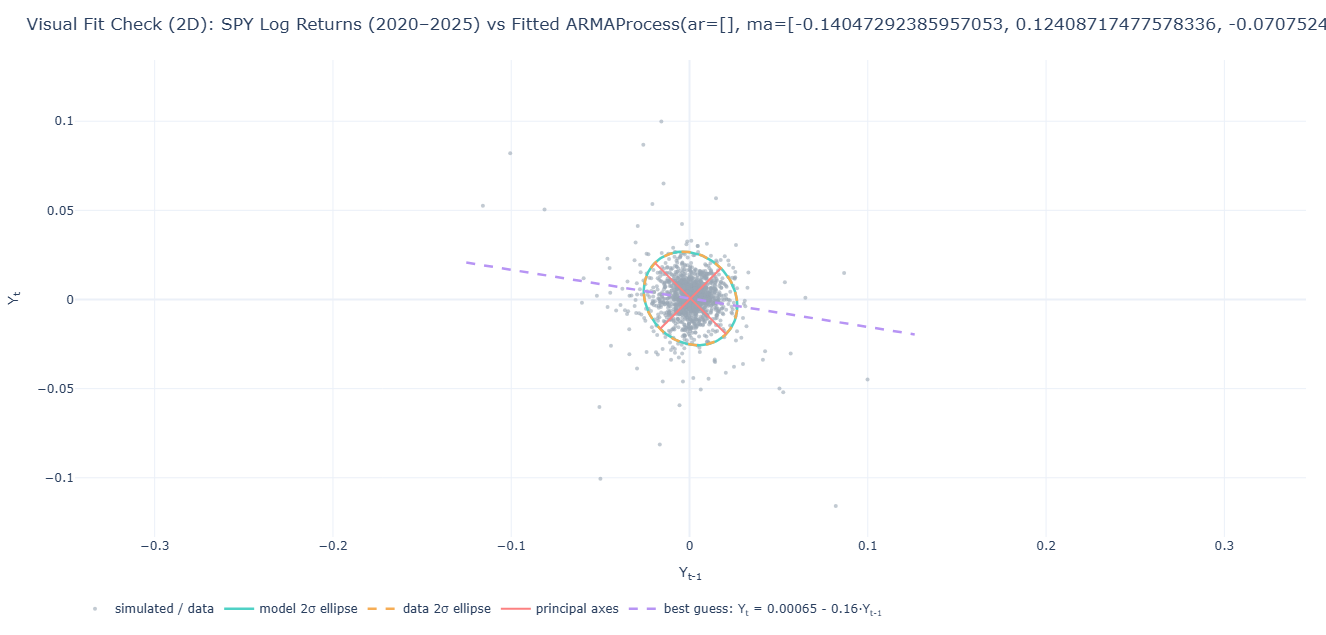

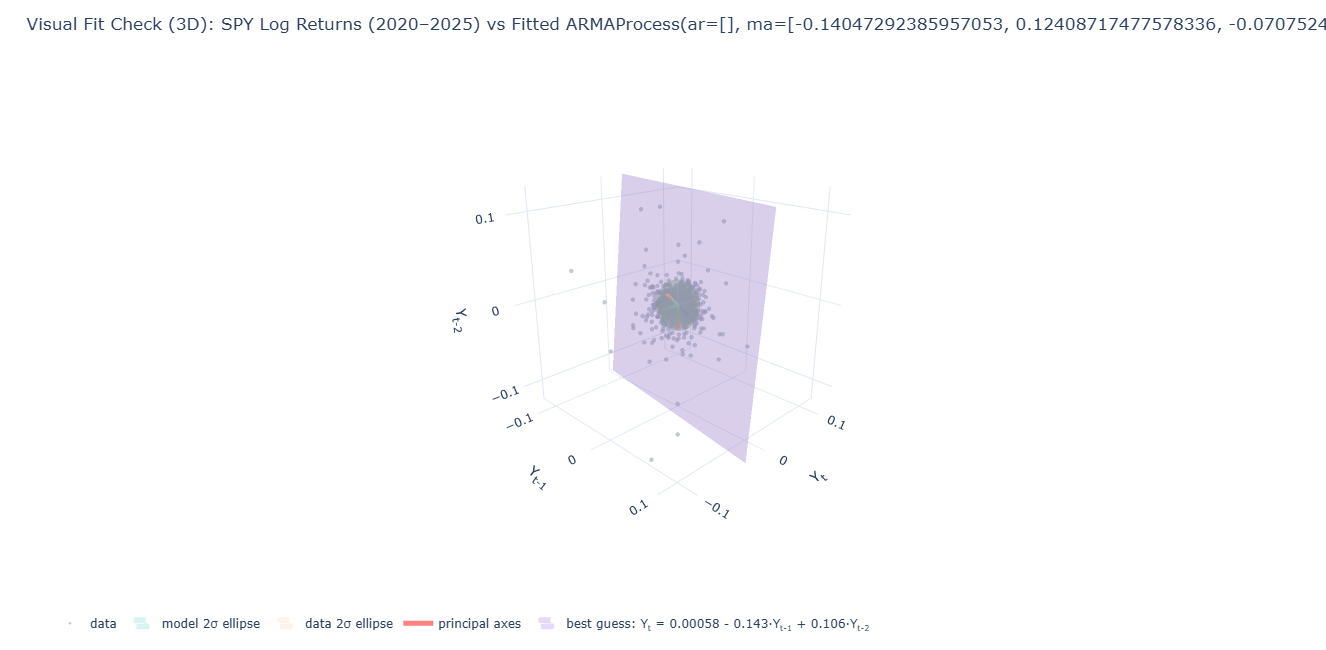

In [16]:
# Visual Fit Verification in 2D (lags=1)
fig_fit_2d = lsp.plot_cloud(
    returns,
    lags=1,
    model=fit.model,
    radius=2.0,
    title=f"Visual Fit Check (2D): {series_name} vs Fitted {fit.model}"
)
fig_fit_2d.show()

# Visual Fit Verification in 3D (lags=2)
fig_fit_3d = lsp.plot_cloud(
    returns,
    lags=2,
    model=fit.model,
    radius=2.0,
    title=f"Visual Fit Check (3D): {series_name} vs Fitted {fit.model}"
)
fig_fit_3d.show()

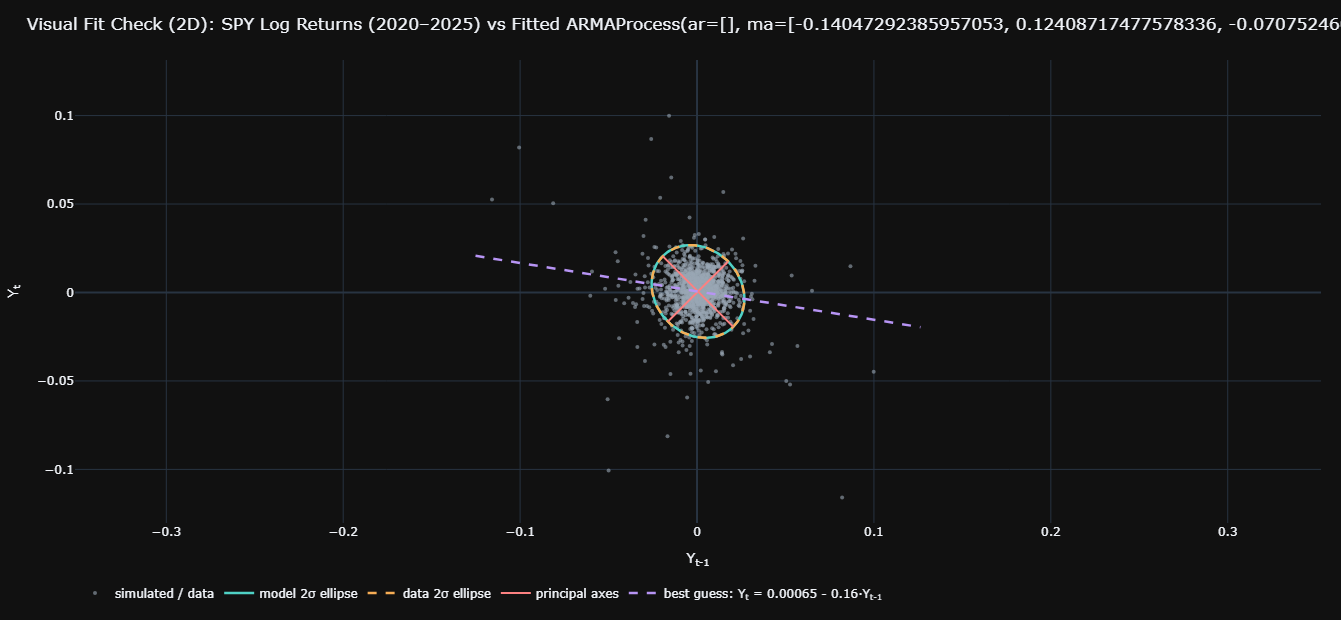

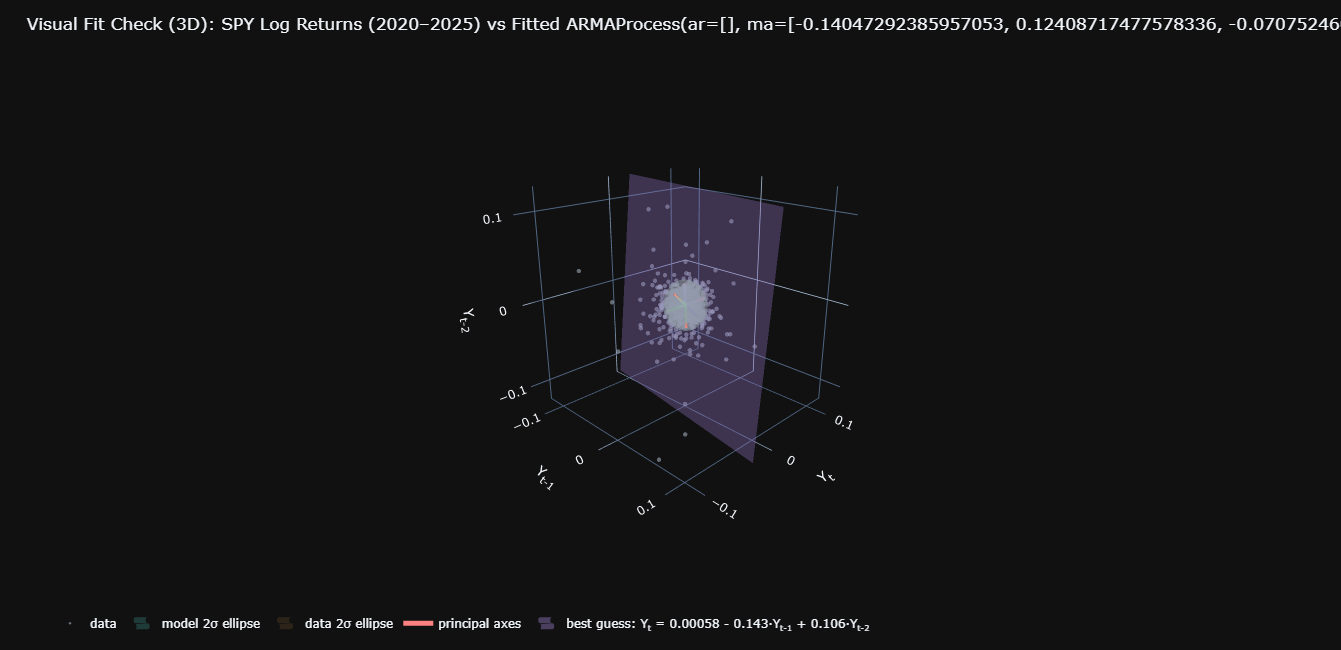

In [24]:
lsp.TEMPLATE = "plotly_dark"
# Visual Fit Verification in 2D (lags=1)
fig_fit_2d = lsp.plot_cloud(
    returns,
    lags=1,
    model=fit.model,
    radius=2.0,
    title=f"Visual Fit Check (2D): {series_name} vs Fitted {fit.model}"
)
fig_fit_2d.show()

# Visual Fit Verification in 3D (lags=2)
fig_fit_3d = lsp.plot_cloud(
    returns,
    lags=2,
    model=fit.model,
    radius=2.0,
    title=f"Visual Fit Check (3D): {series_name} vs Fitted {fit.model}"
)
fig_fit_3d.show()

### 4.5 Out-of-Sample Walk-Forward Forecasting (`walk_forward`)

So far we answered "Does a stationary ARMA$(p,q)$ process match the shape/covariance of this series?"

Now, we forget the fitted model for a moment. We only look at data and ask "f I step through time and build a straight-line lag predictor from past data alone, does it actually predict unseen future values better than just guessing the past average?" which is a valid question and that is probably what everyone will do who haven't seen Time Series Analysis before.

In-sample means testing a model on the same data used to build or fit it. That can look artificially good because the model already saw those numbers. Out-of-sample means the prediction for time `t` is judged on the actual value y_t, which was not used when building the predictor for step `t`. This means this is not really a "prediction", we know the value at time `t` and we just used some amount of data to see how the model has fitted the model. Walk-forward means stepping forward through time one point at a time (`t`):   
- Look only at past data before time `t`.
- Build the best linear guess (a line or hyperplane) from those past observations using `LagCloud.from_data(..., lags).predictor()`.
- Predict the next value `y_t`.
- Move forward to the next time step and repeat.

We have $(y_1, y_2, ..., y_{1506})$ and we choose to use half of it, that is, $(y_1, ..., y_{754})$. We will use `lags=2` and `window=250`. To guess $y_{754}$ we use past $250$ data points - $(y_{504}, ..., y_{753})$.

To forecast $Y_t$, `walk_forward` evaluates a linear function of the 2 most recent values $(Y_{t-1}, Y_{t-2})$:
   $$\hat{Y}_t = c + w_1 Y_{t-1} + w_2 Y_{t-2}$$ where $c$ is `pr.intercept`, $\mathbf{w} = \begin{bmatrix} w_1 \\ w_2 \end{bmatrix}$ is `pr.weights`. We will past $250$ data points to compute $c$ and $\mathbf{w}$. Form the $M \times 3$ lag matrix (`lag_matrix`, where $M = 250 - 2 = 248$ rows):
   $$X = \begin{bmatrix} Y_{t-248} & Y_{t-249} & Y_{t-250} \\ Y_{t-247} & Y_{t-248} & Y_{t-249} \\ \vdots & \vdots & \vdots \\ Y_{t-1} & Y_{t-2} & Y_{t-3} \end{bmatrix}$$
Each row $i$ is a 3D point $\mathbf{x}_i = \begin{bmatrix} x_{i,0} & x_{i,1} & x_{i,2} \end{bmatrix} = \begin{bmatrix} Y_{\tau} & Y_{\tau-1} & Y_{\tau-2} \end{bmatrix}$. Compute the 3-element column sample mean $\boldsymbol{\mu}$ (`pts.mean(axis=0)`):
   $$\boldsymbol{\mu} = \begin{bmatrix} \mu_0 \\ \mu_1 \\ \mu_2 \end{bmatrix} = \frac{1}{M} \sum_{i=1}^{M} \mathbf{x}_i$$
Compute the $3 \times 3$ sample covariance matrix $\Sigma$ (`np.cov(pts, rowvar=False`), using $M - 1$ in the denominator):
   $$\Sigma = \frac{1}{M - 1} \sum_{i=1}^{M} (\mathbf{x}_i - \boldsymbol{\mu})^T (\mathbf{x}_i - \boldsymbol{\mu}) = \begin{bmatrix} \Sigma_{00} & \Sigma_{01} & \Sigma_{02} \\ \Sigma_{10} & \Sigma_{11} & \Sigma_{12} \\ \Sigma_{20} & \Sigma_{21} & \Sigma_{22} \end{bmatrix}$$
Define the past-with-past $2 \times 2$ block $S_{pp}$ and the past-with-present $2 \times 1$ vector $\mathbf{c}$:
   $$S_{pp} = \begin{bmatrix} \Sigma_{11} & \Sigma_{12} \\ \Sigma_{21} & \Sigma_{22} \end{bmatrix}, \qquad \mathbf{c} = \begin{bmatrix} \Sigma_{10} \\ \Sigma_{20} \end{bmatrix}$$
The weights $\mathbf{w}$ solve $S_{pp} \mathbf{w} = \mathbf{c}$:
   $$\begin{bmatrix} w_1 \\ w_2 \end{bmatrix} = \begin{bmatrix} \Sigma_{11} & \Sigma_{12} \\ \Sigma_{21} & \Sigma_{22} \end{bmatrix}^{-1} \begin{bmatrix} \Sigma_{10} \\ \Sigma_{20} \end{bmatrix}$$
And the intercept $c$ is:
   $$c = \mu_0 - (w_1 \mu_1 + w_2 \mu_2)$$

This is the usual minimizing the expected squared prediction error $\mathbb{E}[(Y_t - c - \mathbf{w}^T \mathbf{Y}_{\text{past}})^2]$ over all linear rules. **We have seen it as 2nd order Regression fit with $250$ data points.**

Plug the last `2` values $(y_{753}, y_{752})$ into that predictor to get a guess for $y_{754}$.

Also note the average of those $250$ past points as the simple "benchmark" guess.
Compare your guess to the real `y_754` to see how close we are. Next we do it with `y_755`. We can recompute $\mathbb{w}$ and $c$, but we choose to do it every $5$ steps (as the code will say since we will have the parameter `refit_every` which can be set to 1 if you want).

`walk_forward` computes out-of-sample $R^2$, RMSE, directional hit rate, and the **Clark-West test** $p$-value.

Out-of-sample $R^2$ (`r2_oos`) formulae: We never used the data point (and beyond) $y_{754}$ to calculate the 2nd order Regression coeeficients. Now we will use them to see how good the guess was and also compare with the simple mean ("benchmark") of last $250$ data points. 
$$\bar{y}_{\text{past}, t} = \frac{1}{250} \sum_{j=1}^{250} y_{t-j}$$
That produces one single number ($\bar{y}_{\text{past}, t}$) for day $t$ and this is just the mean.  
$$R^2_{\text{oos}} = 1 - \frac{\displaystyle\sum_{t=754}^{1506} \left(y_t - \hat{y}_t\right)^2}{\displaystyle\sum_{t=754}^{1506} \left(y_t - \bar{y}_{\text{past}, t}\right)^2}$$where for each test day $t \in \{754, 755, \dots, 1506\}$
where $\hat{y}_t$ is the regression we prepared so far.
- If `r2_oos > 0`: The lag-based linear predictor had smaller squared errors than simply guessing the past average.
- If `r2_oos == 0`: The lag-based predictor performed no better and no worse than guessing the past average.
- If `r2_oos < 0`: The lag-based predictor had larger squared errors than simply guessing the past average (it beat you at being wrong).

`sign hit rate` is as the name suggests, gives us the fraction of times when in out of the test steps `forecast` and `actual` matches (these are there because we will not be looking at $753$ data outputs anyway).

In [26]:
wf = lsd.walk_forward(
    returns,
    lags=2,
    train_size=len(returns) // 2,   #so we are using half the available data to find the model
    window=250,       # rolling 250-day window (use None for expanding)
    refit_every=5     # update hyperplane every 5 steps
)
print(wf)
wf.to_frame().tail(10)

walk-forward, lags=2, 753 unseen points
out-of-sample R^2 vs mean forecast  -0.0240   (>0: beats 'predict the historical mean')
RMSE model / benchmark              0.0097772 / 0.0096621
sign hit rate                       0.543
Clark-West p-value (one-sided)      0.849   (small: the lags really add predictive power)


,actual,forecast,benchmark
Date,,,
2025-12-16,-0.002736,-0.000265,0.000525
2025-12-17,-0.011065,0.000764,0.000497
2025-12-18,0.007523,0.001742,0.000470
2025-12-19,0.009023,-0.001388,0.000621
2025-12-22,0.006210,0.000228,0.000658
2025-12-23,0.004560,0.000725,0.000635
2025-12-24,0.003511,0.000658,0.000629
2025-12-26,-0.000101,0.000714,0.000599
2025-12-29,-0.003570,0.001050,0.000599


Since we get $R^2_{oss}$ is negative here, this means our regression based prediction method is working even worse (has more error)!! Even Clark-West p-value is nowhere below $\le 0.05$ and hence lags are not adding any predictive power.

### 4.6 Tracking Regime Drift Over Time (`rolling_cloud`)

This again doesn't have anything to do with fitted model.

We treated our data cloud as if it had one fixed shape across the entire sample. Financial time series rarely keep a static covariance ellipse because volatility spikes inflate the ellipse radius, while shifts in autocorrelation tilt its principal axes. `rolling_cloud` tracks `variance`, `rho1`, `weight_1..k`, `r_squared`, `error_std`, and `elongation` across moving windows, and when `plot=True` (with `lags=1`), automatically renders a **$2 \times 3$ Matplotlib snapshot grid** showing how the 2D ellipse and regression line morph over time.

We will always see 6 plots but we have several of them. When we move one step at a time , that is, `step=1` we get to `Window 2` in $251$ steps. Each plot has last $250$ data points. See next plot to understand the job of `step` and the plot after it to see the function of `plot_steps`.

**Remark: Notice how huge and messy the first oval is. That captures early wild swings (like the 2020 market shock).**

Notice how huge and messy the first oval is. That captures early wild swings (like the 2020 market shock).


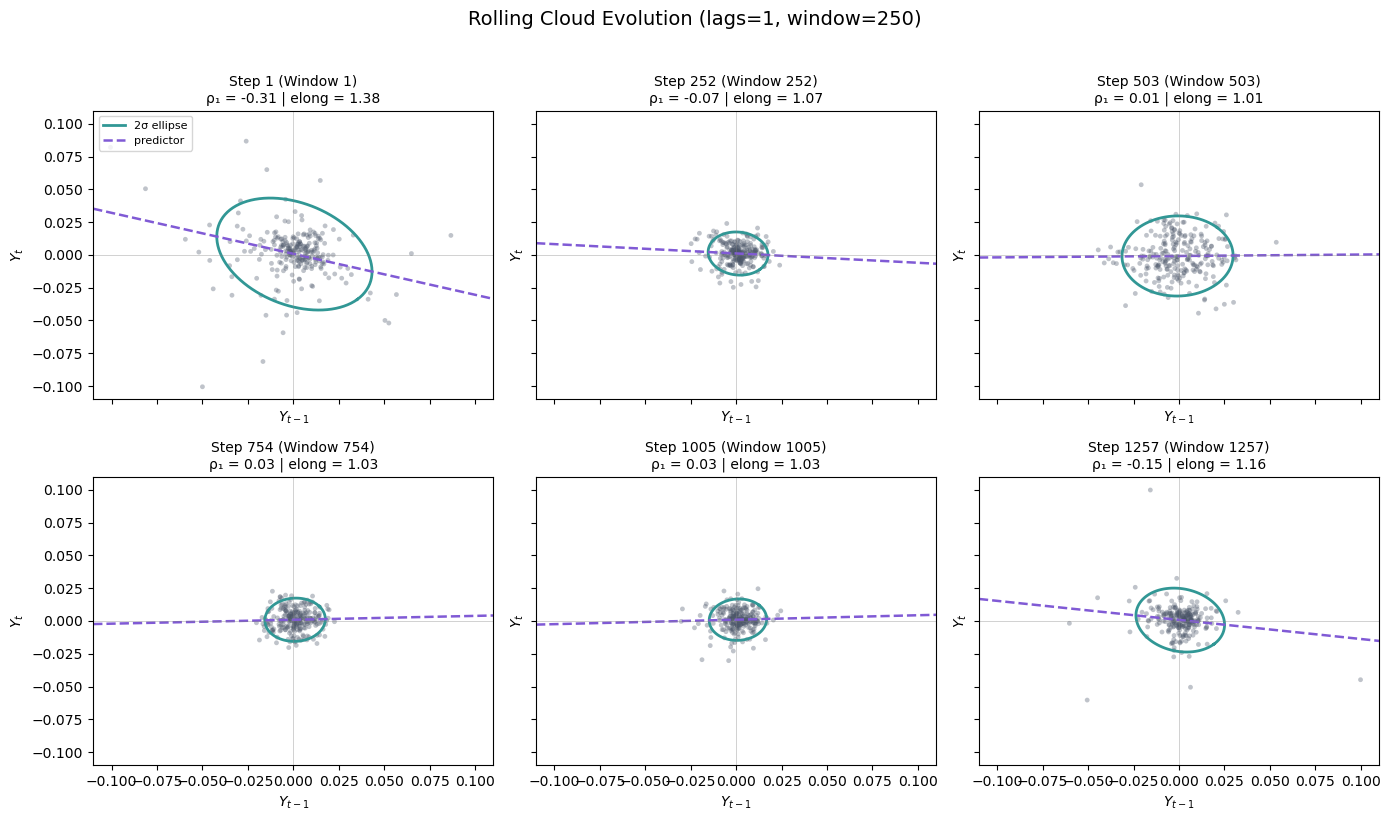

,variance,rho1,weight_1,r_squared,error_std,elongation
Date,,,,,,
2025-12-23,0.000150,-0.139685,-0.139509,0.019512,0.012111,1.150976
2025-12-24,0.000150,-0.139386,-0.139401,0.019428,0.012113,1.150618
2025-12-26,0.000149,-0.139822,-0.139586,0.019550,0.012092,1.151142
2025-12-29,0.000149,-0.143904,-0.143652,0.020708,0.012063,1.155948
2025-12-30,0.000149,-0.145393,-0.145363,0.021139,0.012058,1.157694


In [41]:
# Compute rolling cloud statistics and render the 2x3 evolutionary grid
n_win = len(returns) - 250 + 1
snap_steps = np.linspace(1, n_win, 6, dtype=int).tolist()

df_roll = lsd.rolling_cloud(
    returns,
    lags=1,
    window=250,
    step=1,
    plot=True,
    plot_steps=snap_steps
)
df_roll.tail()

Here we will again have 6 plots (that is the default set up) and since we have around $1500$ data points each will have $250$ still. But now, we will have `step=10` which means we can reach $250$ points ahead in $25$ steps.

The **Window** number of first plot and **Step** number if second plot gives us exactly what the `step` size and number of data points in each window are. Total number of data points in each window is known anyway because total number of data overall data points are known to start with and each window will have $1/6^{th}$ of them.

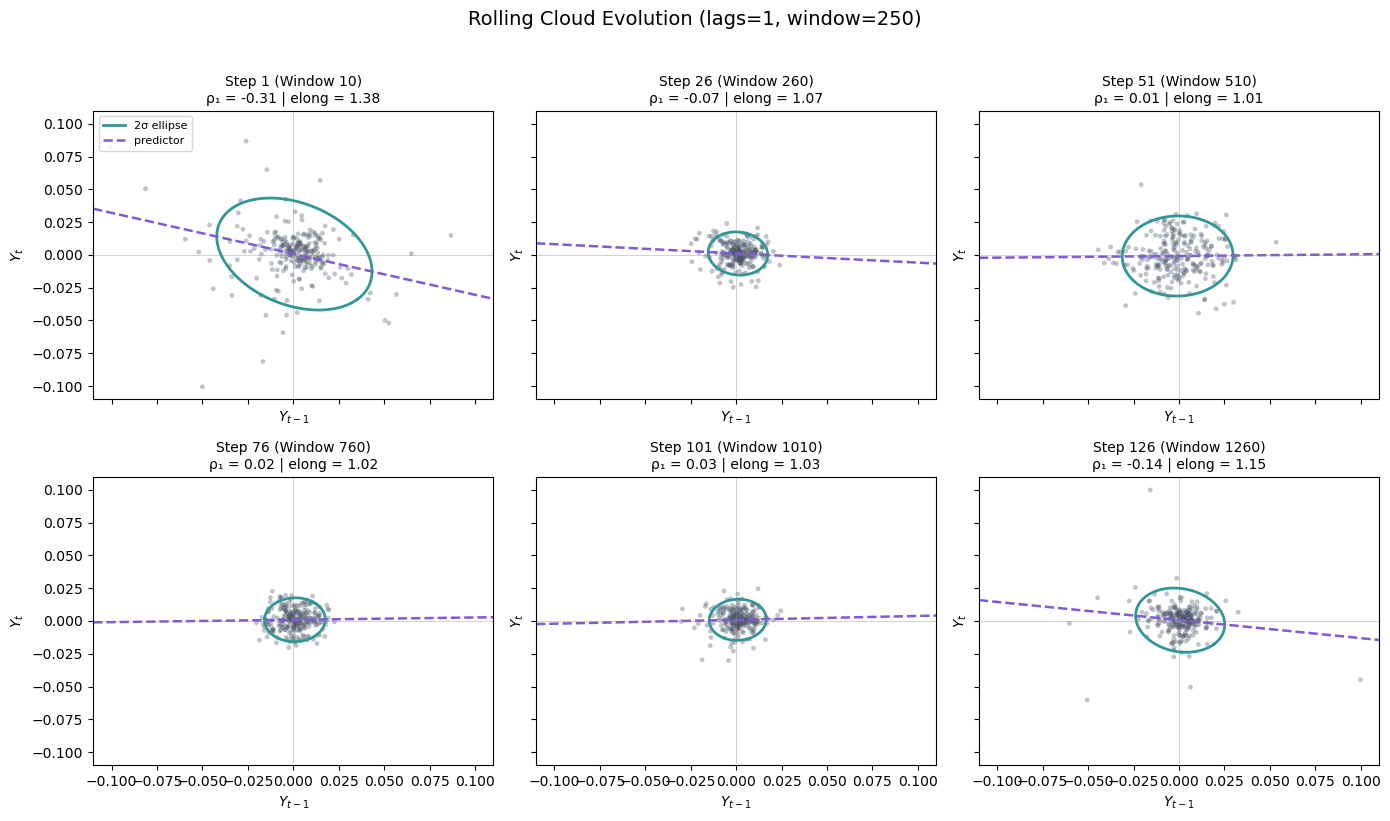

In [34]:
step = 10
n_win = len(np.arange(250, len(returns) + 1, step))
snap_steps = np.linspace(1, n_win, 6, dtype=int).tolist()

df_roll_10 = lsd.rolling_cloud(
    returns,
    lags=1,
    window=250,
    step=step,
    plot=True,
    plot_steps=snap_steps,
)

What if we want to observe the rolling window more closely, as in $12$ or $18$ plots. That is what `plot_steps` is for. We will simply have to run the `rolling_cloud` two times or three times (because each is a batch of $6$) to get $12$ or $18$ respectively.

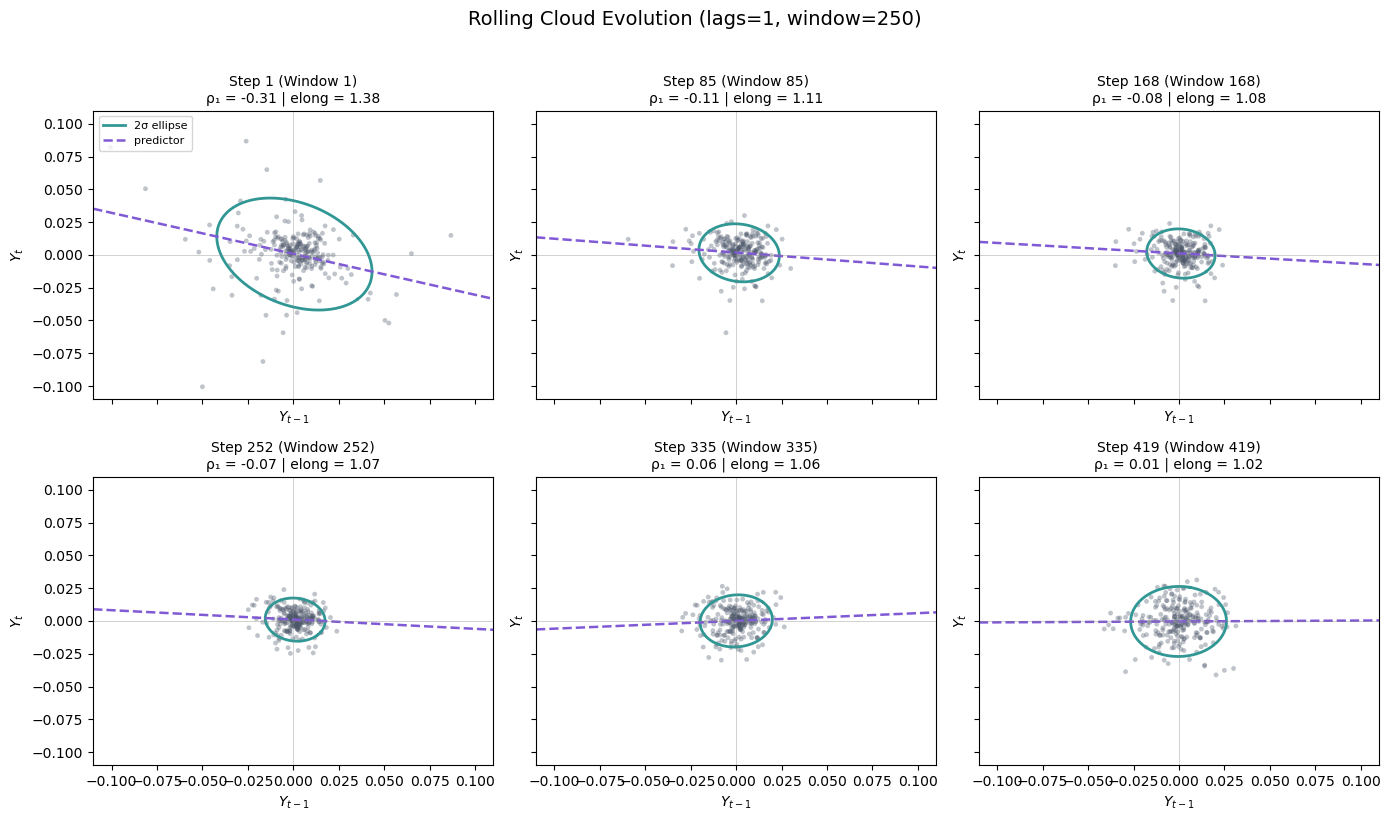

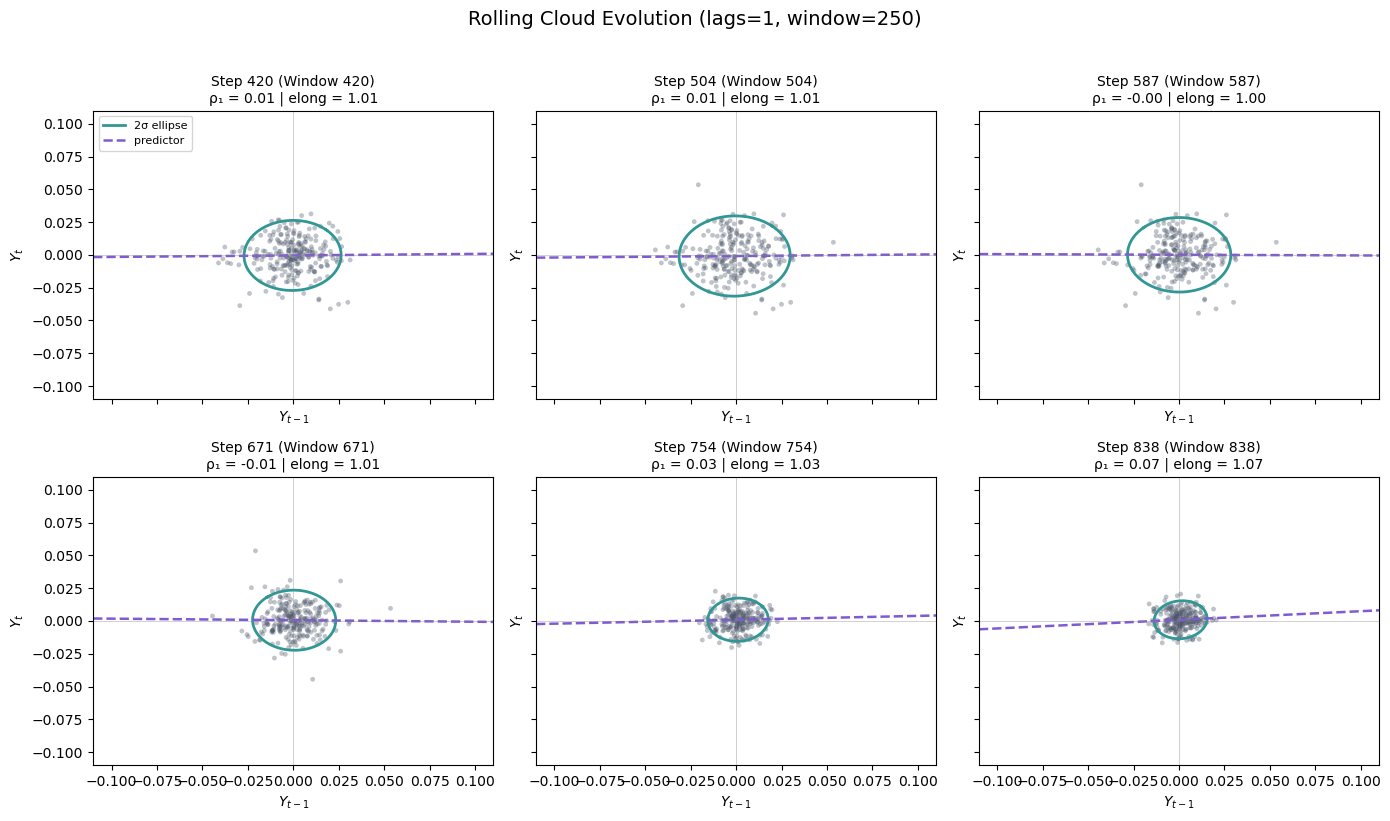

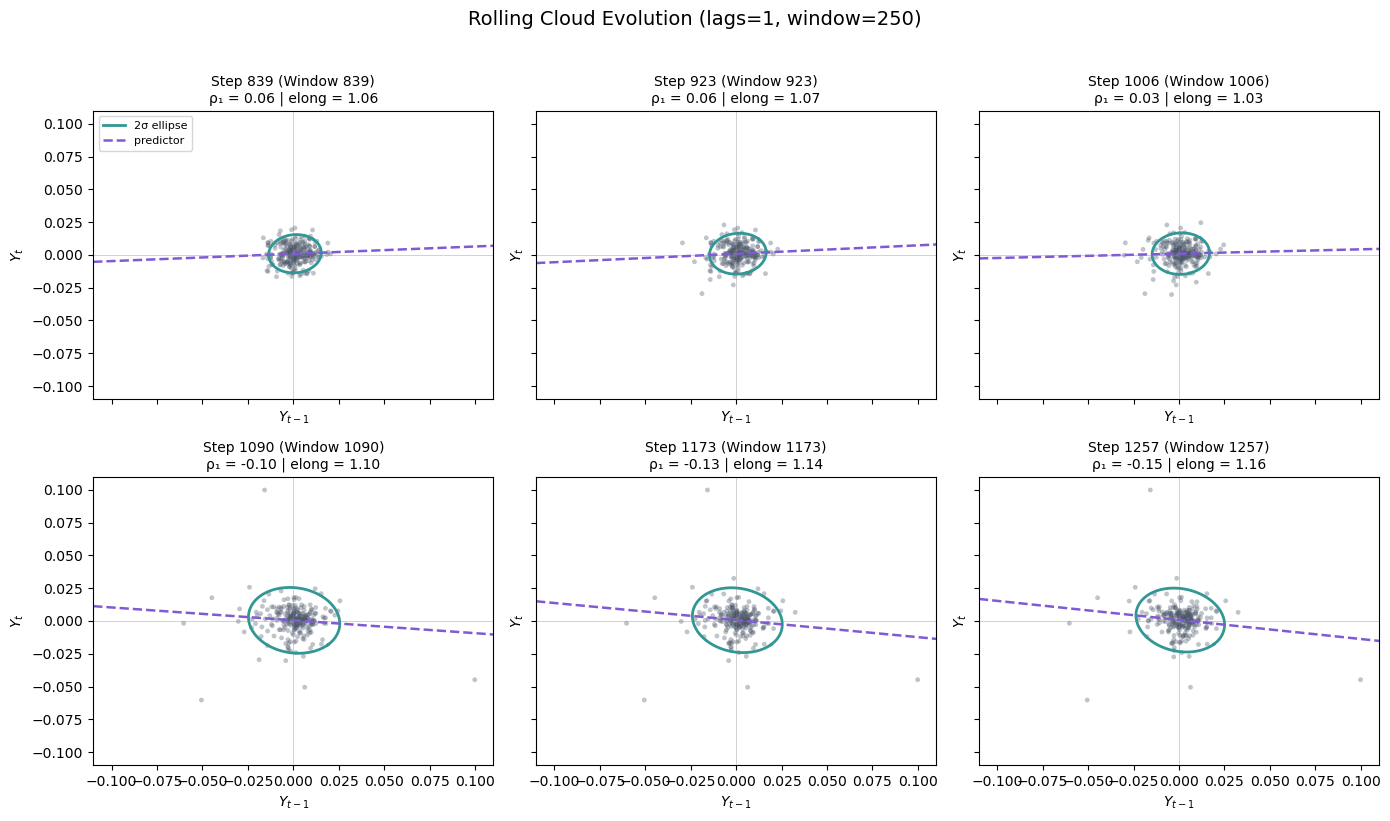

In [46]:
window = 250
step = 1

# Total number of rolling steps for your series
total_steps = len(np.arange(window, len(returns) + 1, step))

# Divide step numbers (1 .. total_steps) into three thirds, 6 steps per third
third = total_steps // 3
steps_part_1 = np.unique(np.round(np.linspace(1, third, 6)).astype(int)).tolist()
steps_part_2 = np.unique(
    np.round(np.linspace(third + 1, 2 * third, 6)).astype(int)
).tolist()
steps_part_3 = np.unique(
    np.round(np.linspace(2 * third + 1, total_steps, 6)).astype(int)
).tolist()

# 1st plot: 6 snapshots from the first 1/3rd
df_part_1 = lsd.rolling_cloud(
    returns, lags=1, window=window, step=step, plot=True, plot_steps=steps_part_1
)

# 2nd plot: 6 snapshots from the middle 1/3rd
df_part_2 = lsd.rolling_cloud(
    returns, lags=1, window=window, step=step, plot=True, plot_steps=steps_part_2
)

# 3rd plot: 6 snapshots from the last 1/3rd
df_part_3 = lsd.rolling_cloud(
    returns, lags=1, window=window, step=step, plot=True, plot_steps=steps_part_3
)

Changing `step` to $1$ or $16$ will not change the picture much (there will be some changes though), it mostly affects how far the window slides every step. 
- `step=15`: First Window is $15^{th}$, second is $90^{th}$ which we reach in $6$ steps.
- `step=1`: First Window is the $1^{st}$ one itself and second is $85^{th}$ one which takes us $85$ steps.

**Remark:** If we want to examine more closely, we can just plot $24$ of them (will record the cloud every $1506/24=62.75\,\sim$ 2 months).

In [21]:
# Compare 2D ellipses across distinct processes and empirical data
clouds_2d = {
    "White Noise":       ls.LagCloud.from_process(ls.ARMAProcess(), lags=1),
    "AR(1) φ = +0.85":   ls.LagCloud.from_process(ls.ARMAProcess(ar=[0.85]), lags=1),
    "MA(1) θ = -0.60":   ls.LagCloud.from_process(ls.ARMAProcess(ma=[-0.60]), lags=1),
    "Empirical Returns": ls.LagCloud.from_data(returns, lags=1),
}
lsp.plot_ellipses(clouds_2d, radius=2.0, title="2D Geometry Comparison Across Processes & Data").show()

# Overlay 3D ellipsoids for two AR(2) regimes
clouds_3d = {
    "Damped Cycle AR(1.2, -0.6)": ls.LagCloud.from_process(ls.ARMAProcess(ar=[1.2, -0.6]), lags=2),
    "Smooth Decay AR(0.6, 0.2)":  ls.LagCloud.from_process(ls.ARMAProcess(ar=[0.6, 0.2]), lags=2),
}
lsp.plot_ellipses(clouds_3d, radius=2.0, title="3D Ellipsoid Overlay (lags=2)").show()
